In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [4]:
df = pd.DataFrame([[153,63], [174,81], [186,91], [128,47], [136,57], [179,76], [163,72], [131,48]])
df.columns = ["x","y"]

In [5]:
df.corr()

,x,y
x,1.000000,0.976581
y,0.976581,1.000000


## Membagi Data

In [6]:
x_train = df['x'].values[:,np.newaxis]
y_train = df['y'].values

x_train

array([[153],
       [174],
       [186],
       [128],
       [136],
       [179],
       [163],
       [131]], dtype=int64)

In [7]:
y_train


array([63, 81, 91, 47, 57, 76, 72, 48], dtype=int64)

## Model Training

In [8]:
lm = LinearRegression()
lm.fit(x_train, y_train)

LinearRegression()

## Membuat Prediksi

In [9]:
x_test = [[170], [160], [180], [171], [150]]

p = lm.predict(x_test)
p

array([76.22496201, 69.42498964, 83.02493438, 76.90495925, 62.62501727])

## Koefisien regresi & Intercept

In [10]:
print("Coefficient :", lm.coef_)
print("Intercept :", lm.intercept_)

Coefficient : [0.67999724]
Intercept : -39.374568310540155


## Visualisasi Model

Text(0, 0.5, 'Nilai y')

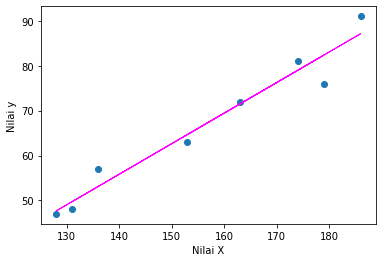

In [12]:
pb = lm.predict(x_train)
dfc = pd.DataFrame({"x" : df["x"], "y" : pb})
plt.scatter(df['x'], df['y'])
plt.plot(dfc['x'], dfc['y'], color="magenta", linewidth=1)
plt.xlabel('Nilai X')
plt.ylabel('Nilai y')

In [13]:
df = pd.read_csv("botak.csv")
df

,umur,jenis_kelamin,pekerjaan,provinsi,gaji,is_menikah,is_keturunan,berat,tinggi,sampo,is_merokok,pendidikan,botak_prob
0,42.0,Laki-laki,PNS,Padang,7.864005e+06,0,0.0,61.928685,152.174164,Deadbuoy,1,S1,0.487655
1,33.0,Laki-laki,Pegawai swasta,Palangkaraya,6.492662e+06,0,0.0,49.374507,152.822969,Moonsilk,1,SMA,0.297270
2,59.0,Laki-laki,Freelance,Serang,8.086303e+06,1,0.0,59.072807,159.911047,Merpati,1,S1,0.467848
3,38.0,Laki-laki,Pegawai swasta,Gorontalo,1.147321e+07,0,1.0,68.338014,162.558997,Moonsilk,0,S1,0.616418
4,33.0,Perempuan,Freelance,Tanjungselor,1.475942e+07,0,0.0,53.769996,154.579510,Pantone,1,S2,0.115439
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7986,31.0,Laki-laki,Pegawai swasta,Padang,2.911963e+07,0,0.0,83.272785,176.020857,Merpati,0,SMA,0.241525
7987,40.0,Perempuan,Pegawai swasta,Banjarmasin,8.955173e+06,0,0.0,61.634474,161.780773,Deadbuoy,0,S1,0.140971
7988,43.0,Perempuan,PNS,Mataram,4.022652e+06,0,0.0,50.525031,152.461656,Shoulder & Head,1,S1,0.364456
7989,29.0,Laki-laki,Pegawai swasta,Serang,5.801753e+06,0,0.0,47.175270,152.749709,NaN,1,SMA,0.248910


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7991 entries, 0 to 7990
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   umur           7991 non-null   float64
 1   jenis_kelamin  7982 non-null   object 
 2   pekerjaan      7924 non-null   object 
 3   provinsi       7991 non-null   object 
 4   gaji           7968 non-null   float64
 5   is_menikah     7991 non-null   int64  
 6   is_keturunan   7976 non-null   float64
 7   berat          7952 non-null   float64
 8   tinggi         7991 non-null   float64
 9   sampo          7934 non-null   object 
 10  is_merokok     7991 non-null   int64  
 11  pendidikan     7991 non-null   object 
 12  botak_prob     7991 non-null   float64
dtypes: float64(6), int64(2), object(5)
memory usage: 811.7+ KB


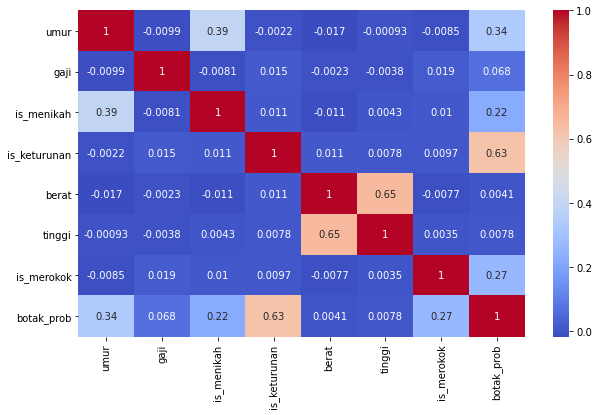

In [17]:
import seaborn as sns

num_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(10,6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm")
plt.show()

In [18]:
db_clean = df.dropna(subset=["umur", "gaji", "tinggi", "berat", "botak_prob"])

x = db_clean[["umur", "gaji", "tinggi", "berat"]]
y = db_clean["botak_prob"]

## Memisah data menjadi data latih dan data test

In [19]:
from sklearn.model_selection import train_test_split as tts

x_train, x_test, y_train, y_test = tts(x, y, test_size=0.2, random_state=0)

In [20]:
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

## Prediksi

In [21]:
y_pred = model.predict(x_test)

In [24]:
#evaluasi

from sklearn.metrics import mean_squared_error, r2_score

print("Coefficient :", model.coef_)
print("Intercept :", model.intercept_)
print("MSE :", mean_squared_error(y_test, y_pred))
print("R2 Score :", r2_score(y_test, y_pred))

Coefficient : [6.62511272e-03 2.82405850e-09 1.98134987e-05 2.24672288e-04]
Intercept : 0.09067104580812368
MSE : 0.03177222988707976
R2 Score : 0.10923976549414827


## Visualisasi Model

<function matplotlib.pyplot.show(close=None, block=None)>

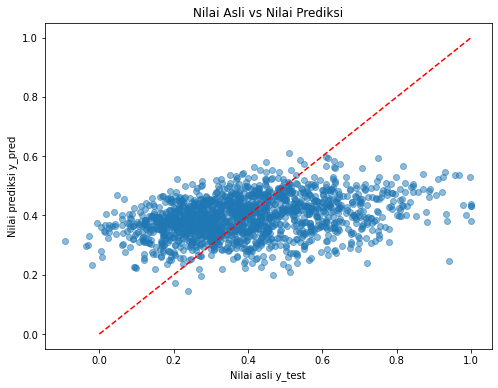

In [26]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.xlabel("Nilai asli y_test")
plt.ylabel("Nilai prediksi y_pred")
plt.title("Nilai Asli vs Nilai Prediksi")
plt.plot([0,1],[0,1], 'r--')
plt.show